# Kieran 학습·frank 평가 데이터 분석

Kieran v2 원본을 학습·내부 검증에, 지정 버전의 frank 리뷰를 외부 평가에 사용했다.
원본 전체 집계와 재검사 결과로 규모·품질·사용자 분리·평가 가능 범위를 정리한다.
이 노트북은 데이터 선택 당시의 분석이다. 이후 데이터 분할과 모델 평가를 완료했다. 최신 결과는 `../reports/forgemaster_model_evaluation.md`, 용어 설명은 `../docs/terminology.md`에 있다.

입력은 미리 정한 게임 목록 안의 리뷰 이력이며, 정답은 그중 사용자가 긍정 평가한 공식 Linux 지원 게임이다.
정답 **한 개를** 숨긴 뒤 긍정·부정 리뷰가 몇 개 남는지 확인한다. 실제 모델 점수에는 긍정 리뷰를 사용하고, 긍정·부정 리뷰 게임 모두 추천에서 제외한다.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

EDA = next(p for p in [Path.cwd()/'EDA', Path.cwd(), *Path.cwd().parents] if (p/'scripts/summarize_kieran_frank.py').exists())
sys.path.insert(0,str(EDA/'scripts'))
from eda_large_review_frank import digest
from readable_labels import setup_korean_font

assert setup_korean_font(), '한글 글꼴이 필요합니다.'
plt.rcParams.update({'figure.facecolor':'white','axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.2,
                     'axes.axisbelow':True,'font.size':10})
m=json.loads((EDA/'reports/kieran_original_frank_eda_metrics.json').read_text('utf-8'))
e=json.loads((EDA/'reports/kieran_frank_eda_metrics.json').read_text('utf-8'))
assert e['source_metric_sha256']==digest(EDA/'reports/kieran_original_frank_eda_metrics.json'), '집계 검증 스크립트를 다시 실행하세요.'
assert e['reference_manifest_sha256']==digest(EDA/'data/reference/manifest.json')
assert m['whole_account_and_cross_review_identity_checks_passed']
assert all(v==0 for v in m['post_exclusion_checks'].values())
assert e['status']['dataset_choice_final'] and not e['status']['final_train_validation_test_files_written']
tables=EDA/'reports/tables'
figures=EDA/'figures'
figures.mkdir(exist_ok=True)

## 1. 두 데이터셋의 규모

Kieran은 원본 주 CSV 전체를, frank는 고정 버전의 선택한 리뷰 열 전체 행을 읽었다.
frank 전체 리뷰 집계는 게임 연결이 모호한 296개 리뷰 ID를 평가 범위에서 제외하기 전 값이다.

In [2]:
sources=pd.DataFrame([
    {'자료':'Kieran 원본','원본 리뷰 행':m['raw_quality']['raw_rows'],
     '정리 후 사용자–게임 쌍':m['clean_source']['pairs'],'계정':m['clean_source']['users'],
     '게임':m['clean_source']['apps'],'역할':'학습·내부 검증'},
    {'자료':'frank 리뷰','원본 리뷰 행':e['frank_provenance']['raw_rows'],
     '정리 후 사용자–게임 쌍':e['frank_full_review_summary']['clean_pairs'],
     '계정':e['frank_full_review_summary']['users'],'게임':e['frank_full_review_summary']['apps'],
     '역할':'외부 테스트 원천'}])
display(sources)
print('Kieran 긍정 비율:',f"{m['clean_source']['positives']/m['clean_source']['pairs']:.2%}")
print('Kieran 사용자별 리뷰 게임 수 중앙값/p90/p99:',*[m['clean_source']['history_quantiles'][i] for i in [1,3,4]])

,자료,원본 리뷰 행,정리 후 사용자–게임 쌍,계정,게임,역할
0,Kieran 원본,113883717,113195034,37875512,105838,학습·내부 검증
1,frank 리뷰,2631430,2631416,1336109,44517,외부 테스트 원천


Kieran 긍정 비율: 85.60%
Kieran 사용자별 리뷰 게임 수 중앙값/p90/p99: 1 6 25


## 2. 품질 검사와 충돌 리뷰 제외

원 계정 ID는 float로 읽지 않는다. 같은 원 리뷰가 다른 게임에 연결된 경우는
어느 게임이 맞는지 추측하지 않고 해당 리뷰 ID의 모든 행을 제외했다.

In [3]:
q=m['raw_quality']
quality=pd.DataFrame([
    ('형식·결측 무효 행',q['quarantined_rows'],'사용 제외'),
    ('원 리뷰 ID의 계정 충돌',q['review_ids_with_conflicting_owner'],'계정 정밀도 검사'),
    ('원 리뷰 ID의 게임 충돌',q['review_ids_with_conflicting_app'],'해당 ID 전체 격리'),
    ('게임 충돌 ID에 속한 행',q['rows_with_conflicting_review_identity'],'686,161행 격리'),
    ('frank 대조 추가 격리 ID',q['additional_cross_source_review_ids_quarantined'],'추가 3개 ID 격리'),
    ('같은 라벨 반복 행',q['same_label_duplicate_rows'],'중복 제거'),
    ('긍정·부정 충돌 쌍',q['conflicting_label_pairs'],'쌍 전체 격리'),
    ('플레이 시간 결측 행',q['raw_rows']-m['raw_playtime']['rows_with_playtime'],'0분과 구분'),
    ('갱신 시각 역전 행',q['updated_before_created'],'시간 정보 한계 기록')],
    columns=['검사','수','처리·해석'])
display(quality)
quality.to_csv(tables/'03_kieran_quality.csv',index=False,encoding='utf-8-sig')

,검사,수,처리·해석
0,형식·결측 무효 행,0,사용 제외
1,원 리뷰 ID의 계정 충돌,0,계정 정밀도 검사
2,원 리뷰 ID의 게임 충돌,332865,해당 ID 전체 격리
3,게임 충돌 ID에 속한 행,686161,"686,161행 격리"
4,frank 대조 추가 격리 ID,3,추가 3개 ID 격리
5,같은 라벨 반복 행,2375,중복 제거
6,긍정·부정 충돌 쌍,72,쌍 전체 격리
7,플레이 시간 결측 행,8,0분과 구분
8,갱신 시각 역전 행,2,시간 정보 한계 기록


## 3. 평가·검증 계정의 학습 제외

frank 평가에 사용할 가능성이 있는 계정 87,573명을 학습에서 미리 제외한다. 그중 Kieran에도 있는
79,879계정의 모든 게임 3,360,025쌍을 제외했다. 검증 계정은 나머지 원 계정의
계정 ID의 MD5 해시값으로 약 10%를 검증용으로 분리했다. 아래는 최종 분할 파일을 만들기 전 예상 규모다.

In [4]:
splits=pd.DataFrame([{'단계':label,'계정':m[key]['users'],'리뷰 쌍':m[key]['pairs'],
                      '긍정 쌍':m[key]['positives']} for key,label in [
    ('clean_source','정리 후 전체'),('after_test_exclusion','테스트 계정 제외 후'),
    ('validation_preview','내부 검증 예약'),('after_validation_reservation','학습안')]])
display(splits)
splits.to_csv(tables/'01_main_split_preview.csv',index=False,encoding='utf-8-sig')
display(pd.DataFrame([{'검사':k,'교집합':v} for k,v in m['post_exclusion_checks'].items()]))
assert splits.iloc[1]['리뷰 쌍']==splits.iloc[2]['리뷰 쌍']+splits.iloc[3]['리뷰 쌍']
print('원 리뷰 공유:',f"{m['cross_source_overlap']['common_original_review_ids']:,}",
      '/ 작성자 불일치:',m['cross_source_overlap']['common_review_ids_with_different_owner'])

,단계,계정,리뷰 쌍,긍정 쌍
0,정리 후 전체,37875512,113195034,96891267
1,테스트 계정 제외 후,37795633,109835009,94206307
2,내부 검증 예약,3781518,10977308,9414990
3,학습안,34014115,98857701,84791317


,검사,교집합
0,remaining_train_test_user_intersection,0
1,remaining_train_test_user_app_intersection,0
2,remaining_train_test_original_review_id_inters...,0


원 리뷰 공유: 1,089,913 / 작성자 불일치: 0


## 4. frank 평가 후보

알려진 리뷰–게임 연결 모호성 296개 ID의 영향을 받는 사용자–게임 쌍을 제거했다.
학습에서 제외한 전체 87,573계정 목록은 유지한다. 입력 수는 긍정·부정 리뷰를 함께 세며,
숨긴 정답 외 다른 긍정 입력의 존재도 따로 보고한다.

In [5]:
cohort=pd.DataFrame(e['cohorts']['safe_mapping_fixed_catalog']).rename(columns={
    'minimum_inputs':'최소 다른 입력','potential_users':'평가 후보',
    'potential_users_with_positive_query':'긍정 입력도 남는 후보',
    'potential_users_with_only_negative_query':'부정 입력만 남는 후보',
    'possible_target_pairs':'선택 전 가능한 정답 쌍'})
display(cohort)
cohort.to_csv(tables/'02_frank_eligibility.csv',index=False,encoding='utf-8-sig')
support=[]
for key,label in [('safe_mapping_fixed_catalog','고정 평가 범위'),
                  ('safe_mapping_kieran_review_support','모든 입력·정답에 학습 리뷰 있음'),
                  ('safe_mapping_kieran_positive_support_5','모든 입력·정답에 긍정 학습 계정 ≥5')]:
    row=next(r for r in e['cohorts'][key] if r['minimum_inputs']==5)
    support.append({'조건':label,'입력 ≥5 후보':row['potential_users'],
                    '긍정 입력도 남는 후보':row['potential_users_with_positive_query']})
display(pd.DataFrame(support))
print('지원 조건은 진단입니다. 모델별로 어려운 사용자를 평가 명단에서 제거하지 않습니다.')

,최소 다른 입력,평가 후보,긍정 입력도 남는 후보,부정 입력만 남는 후보,선택 전 가능한 정답 쌍
0,1,87557,78228,9329,184082
1,3,39450,38549,901,125593
2,5,24571,24342,229,102602
3,10,11647,11609,38,76056


,조건,입력 ≥5 후보,긍정 입력도 남는 후보
0,고정 평가 범위,24571,24342
1,모든 입력·정답에 학습 리뷰 있음,24479,24250
2,모든 입력·정답에 긍정 학습 계정 ≥5,24339,24108


지원 조건은 진단입니다. 모델별로 어려운 사용자를 평가 명단에서 제거하지 않습니다.


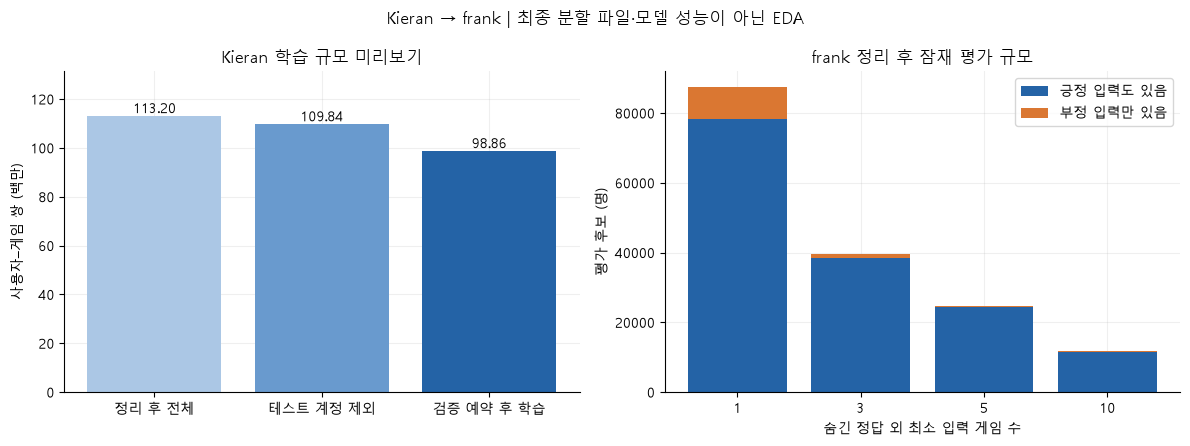

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
counts=[m[k]['pairs']/1_000_000 for k in ['clean_source','after_test_exclusion','after_validation_reservation']]
axes[0].bar(['정리 후 전체','테스트 계정 제외','검증 예약 후 학습'],counts,color=['#abc7e5','#699ace','#2463a6'])
axes[0].set_ylabel('사용자–게임 쌍 (백만)')
axes[0].set_title('Kieran 학습 규모 미리보기')
axes[0].set_ylim(0,max(counts)*1.16)
for i,y in enumerate(counts): axes[0].text(i,y+1,f'{y:.2f}',ha='center')
x=range(len(cohort))
axes[1].bar(x,cohort['긍정 입력도 남는 후보'],label='긍정 입력도 있음',color='#2463a6')
axes[1].bar(x,cohort['부정 입력만 남는 후보'],bottom=cohort['긍정 입력도 남는 후보'],label='부정 입력만 있음',color='#da7732')
axes[1].set_xticks(list(x),[str(v) for v in cohort['최소 다른 입력']])
axes[1].set_xlabel('숨긴 정답 외 최소 입력 게임 수')
axes[1].set_ylabel('평가 후보 (명)')
axes[1].set_title('frank 정리 후 잠재 평가 규모')
axes[1].legend()
fig.suptitle('Kieran → frank | 최종 분할 파일·모델 성능이 아닌 EDA')
fig.tight_layout()
fig.savefig(figures/'fig01_kieran_frank_overview.png',dpi=160,bbox_inches='tight')
plt.show()

## 5. 리뷰 시기와 게임 정보 연결

Kieran 원본은 2010–2023년 다국어 리뷰다. 시간순 분할은 수행하지 않았다.
게임 목록과 설명·태그의 존재 여부는 별도 참조 파일로 관리한다.
설명·태그 존재는 실제 텍스트 품질과 모델 성능을 뜻하지 않는다.

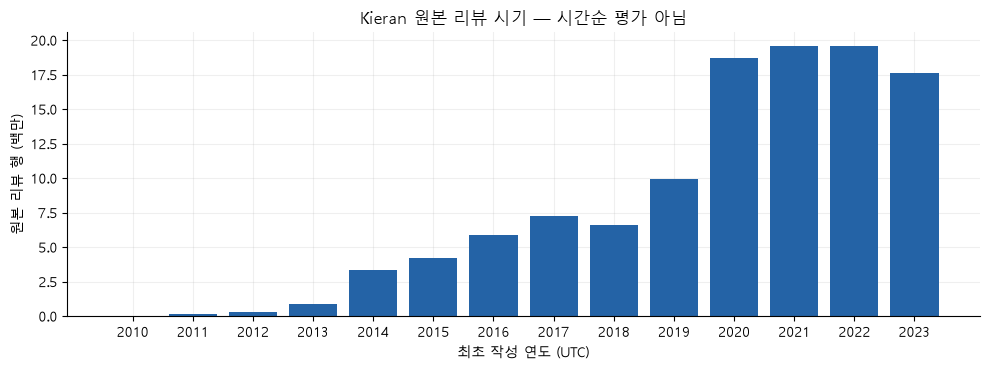

,고정 입력 게임,고정 Linux 후보,학습 리뷰가 남는 Linux 게임,원본 게임 중 메타데이터 미연결
0,37610,6630,6603,28867


In [7]:
years=pd.DataFrame(m['raw_created_years'])
fig,ax=plt.subplots(figsize=(10,3.8))
ax.bar(years['review_created_year'],years['raw_rows']/1_000_000,color='#2463a6')
ax.set(xlabel='최초 작성 연도 (UTC)',ylabel='원본 리뷰 행 (백만)',title='Kieran 원본 리뷰 시기 — 시간순 평가 아님')
fig.tight_layout()
fig.savefig(figures/'fig02_kieran_review_years.png',dpi=160,bbox_inches='tight')
plt.show()
display(pd.DataFrame([{'고정 입력 게임':e['catalog']['input_apps'],
    '고정 Linux 후보':e['catalog']['linux_target_apps'],
    '학습 리뷰가 남는 Linux 게임':m['after_validation_reservation']['linux_apps_in_fixed_catalog'],
    '원본 게임 중 메타데이터 미연결':m['metadata_coverage']['source_apps_without_A_or_C_metadata']}]))

## 6. 분석 당시 정한 후속 작업

- 최소 입력 수·긍정 입력 조건·정답 선택 규칙을 정하고 학습·검증·평가 파일을 만든다.
- 저장 파일을 다시 읽어 계정·원 리뷰·사용자–게임 쌍이 학습과 평가에 중복되지 않고 정답이 입력에 없는지 확인한다.
- 인기도·공동 출현·이웃·특징은 학습에서만 계산하고 모델 선택은 검증셋에서 한다.
- frank의 게임당 최대 100개 리뷰 제한과 활동이 많은 리뷰어에 치우친 표본을 결과에 함께 설명한다.
- Kieran 플레이 시간은 수집 시점의 리뷰 작성자 정보다. 전체 보유 게임 목록을 뜻하지 않는다.

이전 A/B/C·후보 비교·artermiloff 제외 증거는 `legacy/`에 보존한다.
이 분석의 요약은 `../reports/kieran_frank_eda.md`, 출처와 열 설명은 `../docs/datasets/`에 있다.